# Gaussian-process regression: prediction and uncertainty

**Sheima Alameeri, PhD**

A standalone tutorial using a newly generated, one-dimensional synthetic dataset.

You will learn to:
- Construct an RBF covariance kernel and condition a GP on noisy observations.
- Distinguish uncertainty about a latent function from uncertainty about a future observation.
- Explore the influence of the length scale and the limits of extrapolation.
- Check a direct Cholesky implementation against scikit-learn.

Prerequisites: basic Python, regression, and matrix algebra. No downloaded data, GPU, or external service is required. This example is independent of my dissertation implementation.


## 1. Model and assumptions

We observe $y_i=f(x_i)+\epsilon_i$, with independent Gaussian noise $\epsilon_i\sim N(0,\sigma_n^2)$. We use a zero-mean GP and an RBF kernel:

$$k(x,x')=\sigma_f^2\exp\left[-\frac{(x-x')^2}{2\ell^2}\right].$$

For a test input, let $A=K(X,X)+\sigma_n^2I$. Conditioning a multivariate Gaussian gives:

$$\mu_*=K(X,X_*)^T A^{-1}y,$$
$$\Sigma_*=K(X_*,X_*)-K(X,X_*)^T A^{-1}K(X,X_*).$$

We compute these expressions with Cholesky solves, without explicitly forming an inverse. A tiny diagonal jitter is added for numerical stability.

The noise standard deviation, signal standard deviation, and length scale are **fixed** in this tutorial. We do not estimate them or integrate over their uncertainty. The synthetic truth is a fixed function, not a draw from our GP prior.


In [1]:
from pathlib import Path
import platform
import numpy as np
import scipy
from scipy.linalg import cho_solve, solve_triangular
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF

SEED = 2026
NOISE_STD = 0.18
SIGNAL_STD = 1.0
LENGTH_SCALE = 1.0
JITTER = 1e-10
Z95 = 1.959963984540054
ASSETS = Path('assets')
ASSETS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})

print(f'Python {platform.python_version()} | NumPy {np.__version__} | '
      f'SciPy {scipy.__version__} | scikit-learn {sklearn.__version__} | '
      f'Matplotlib {matplotlib.__version__} | pandas {pd.__version__}')
print(f'Random seed: {SEED}')


Python 3.12.14 | NumPy 2.3.5 | SciPy 1.17.0 | scikit-learn 1.8.0 | Matplotlib 3.10.8 | pandas 2.2.3
Random seed: 2026


## 2. Generate observations

We sample 18 training inputs between -3 and 3 and add Gaussian measurement noise. The true curve is known only because we designed this teaching example. Inputs outside the training range will let us examine extrapolation.


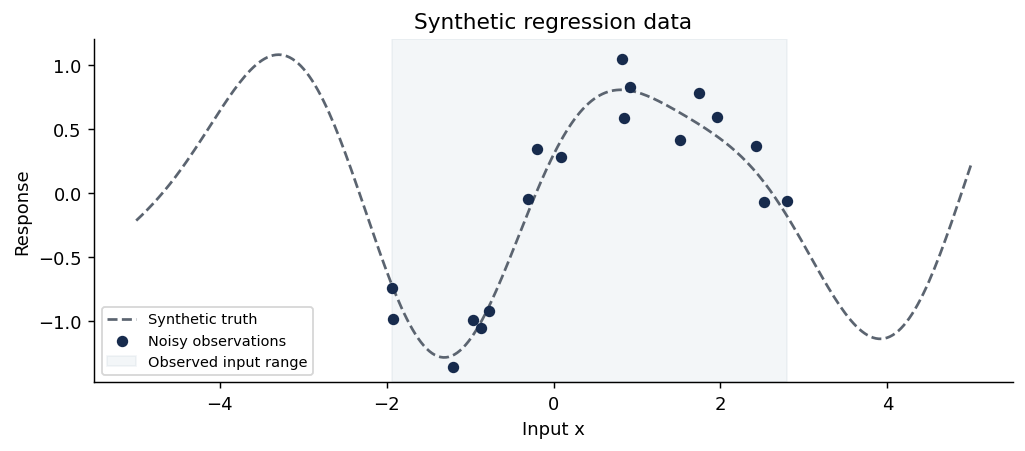

In [2]:
def truth(x):
    x = np.asarray(x).reshape(-1)
    return np.sin(1.3 * x) + 0.3 * np.cos(2.2 * x)

rng = np.random.default_rng(SEED)
X_train = np.sort(rng.uniform(-3.0, 3.0, 18)).reshape(-1, 1)
y_train = truth(X_train) + rng.normal(0.0, NOISE_STD, len(X_train))
X_grid = np.linspace(-5.0, 5.0, 300).reshape(-1, 1)
x_grid = X_grid[:, 0]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(x_grid, truth(X_grid), '--', color='#5b6470', label='Synthetic truth')
ax.scatter(X_train[:, 0], y_train, color='#172b4d', s=28, label='Noisy observations', zorder=3)
ax.axvspan(X_train.min(), X_train.max(), color='#205178', alpha=0.05, label='Observed input range')
ax.set(xlabel='Input x', ylabel='Response', title='Synthetic regression data')
ax.legend(loc='lower left', fontsize=8)
fig.tight_layout()
fig.savefig(ASSETS / 'synthetic-data.png', dpi=160)
plt.show()


## 3. Compute the posterior

The kernel expresses an assumption about similarity: nearby inputs have more strongly correlated function values. The length scale controls how quickly this correlation decays.

The implementation below returns the posterior mean and **latent-function** standard deviation. Input arrays have shape `(number_of_points, number_of_features)`; our example has one feature.


In [3]:
def rbf_kernel(X, Z, length_scale=1.0, signal_std=1.0):
    distances = np.sum((X[:, None, :] - Z[None, :, :]) ** 2, axis=2)
    return signal_std ** 2 * np.exp(-0.5 * distances / length_scale ** 2)

def posterior(X_train, y_train, X_test, length_scale=LENGTH_SCALE):
    K = rbf_kernel(X_train, X_train, length_scale, SIGNAL_STD)
    A = K + (NOISE_STD ** 2 + JITTER) * np.eye(len(X_train))
    L = np.linalg.cholesky(A)
    weights = cho_solve((L, True), y_train)
    K_cross = rbf_kernel(X_train, X_test, length_scale, SIGNAL_STD)
    mean = K_cross.T @ weights
    projected = solve_triangular(L, K_cross, lower=True)
    variance = SIGNAL_STD ** 2 - np.sum(projected ** 2, axis=0)
    if variance.min() < -1e-8:
        raise ArithmeticError('Unexpectedly negative posterior variance.')
    return mean, np.sqrt(np.maximum(variance, 0.0))

mean, latent_std = posterior(X_train, y_train, X_grid)
observation_std = np.sqrt(latent_std ** 2 + NOISE_STD ** 2)

# Verify against a separate library implementation with identical assumptions.
kernel = ConstantKernel(SIGNAL_STD ** 2, constant_value_bounds='fixed') * RBF(
    LENGTH_SCALE, length_scale_bounds='fixed')
reference = GaussianProcessRegressor(kernel=kernel, alpha=NOISE_STD ** 2 + JITTER,
                                    optimizer=None, normalize_y=False)
reference.fit(X_train, y_train)
reference_mean, reference_std = reference.predict(X_grid, return_std=True)
np.testing.assert_allclose(mean, reference_mean, atol=1e-8, rtol=1e-8)
np.testing.assert_allclose(latent_std, reference_std, atol=1e-8, rtol=1e-8)
np.testing.assert_allclose(observation_std ** 2 - latent_std ** 2, NOISE_STD ** 2,
                           atol=1e-12)
assert np.all(np.isfinite(mean)) and np.all(np.isfinite(observation_std))
print('Checks passed: posterior agrees with scikit-learn; observation variance '
      'equals latent variance plus noise variance.')


Checks passed: posterior agrees with scikit-learn; observation variance equals latent variance plus noise variance.


## 4. Two different uncertainty intervals

For the latent function, the marginal posterior interval at each input is $\mu(x)\pm 1.96s_f(x)$. For a **new noisy observation**, add the measurement-noise variance:

$$s_y^2(x)=s_f^2(x)+\sigma_n^2.$$

The future-observation interval is wider, even where the function is well determined. These are **pointwise, model-based 95% intervals**, conditional on the chosen kernel and fixed hyperparameters. They are not simultaneous bands or a guarantee of 95% empirical coverage for this fixed synthetic truth.

With the zero-mean RBF prior, predictions tend toward zero and latent uncertainty tends toward its prior level far from the observed inputs. Wider uncertainty does not imply that extrapolated predictions are accurate.


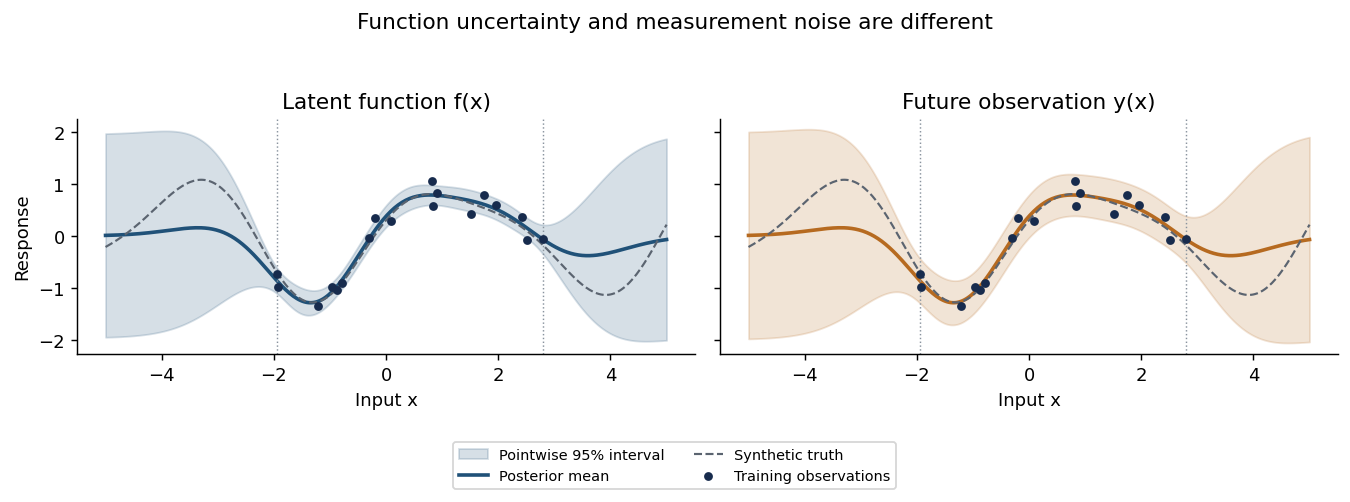

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, std, color, title in zip(
        axes, [latent_std, observation_std], ['#205178', '#b66a20'],
        ['Latent function f(x)', 'Future observation y(x)']):
    ax.fill_between(x_grid, mean - Z95 * std, mean + Z95 * std,
                    color=color, alpha=0.18, label='Pointwise 95% interval')
    ax.plot(x_grid, mean, color=color, lw=2, label='Posterior mean')
    ax.plot(x_grid, truth(X_grid), '--', color='#5b6470', lw=1.2, label='Synthetic truth')
    ax.scatter(X_train[:, 0], y_train, s=15, color='#172b4d', zorder=3,
               label='Training observations')
    ax.axvline(X_train.min(), color='#89939e', lw=0.8, ls=':')
    ax.axvline(X_train.max(), color='#89939e', lw=0.8, ls=':')
    ax.set(xlabel='Input x', title=title)
axes[0].set_ylabel('Response')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=8,
           bbox_to_anchor=(0.5, 0.0))
fig.suptitle('Function uncertainty and measurement noise are different', fontsize=12)
fig.tight_layout(rect=(0, 0.13, 1, 0.94))
fig.savefig(ASSETS / 'gp-uncertainty.png', dpi=170)
plt.show()


## 5. Change the length scale

Keep the observations, signal amplitude, and noise level unchanged. A short length scale permits rapid variation; a long one favors smoother variation. This comparison illustrates assumptions rather than selecting a winning model: no test data are used to tune the settings.


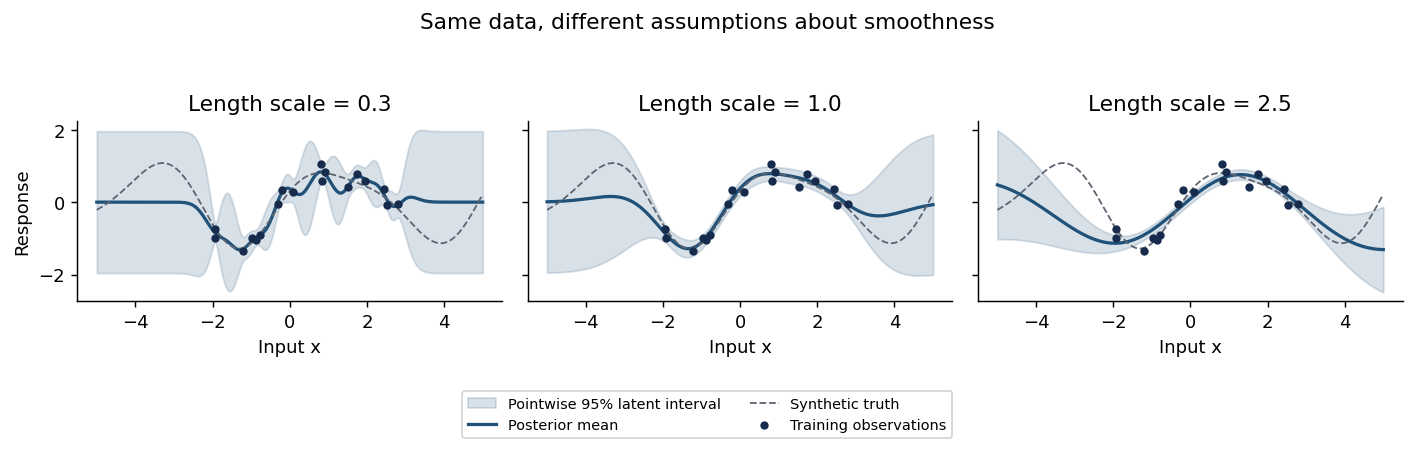

In [5]:
length_scales = [0.3, 1.0, 2.5]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, length in zip(axes, length_scales):
    mu, sd = posterior(X_train, y_train, X_grid, length_scale=length)
    ax.fill_between(x_grid, mu - Z95 * sd, mu + Z95 * sd, color='#205178', alpha=0.17,
                    label='Pointwise 95% latent interval')
    ax.plot(x_grid, mu, color='#205178', lw=1.8, label='Posterior mean')
    ax.plot(x_grid, truth(X_grid), '--', color='#5b6470', lw=1, label='Synthetic truth')
    ax.scatter(X_train[:, 0], y_train, color='#172b4d', s=13, zorder=3,
               label='Training observations')
    ax.set(xlabel='Input x', title=f'Length scale = {length}')
axes[0].set_ylabel('Response')
fig.suptitle('Same data, different assumptions about smoothness', fontsize=12)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=8,
           bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.15, 1, 0.93))
fig.savefig(ASSETS / 'length-scale-comparison.png', dpi=160)
plt.show()


## 6. Evaluate new noisy observations

Generate fresh test inputs and noise using a separate random stream. Define interpolation as the observed input range and extrapolation as the remaining parts of [-5, 5]. Evaluate the original length-scale-1 model without retuning it.

We report root mean squared error (RMSE), negative log predictive density (NLPD), the fraction of new noisy outcomes inside the pointwise predictive intervals, and their mean width. Lower RMSE and NLPD are better; width must be interpreted alongside coverage. This is one small illustration, not a repeated-sampling calibration study. Nearby errors can be related through the fitted function, so the coverage percentages are descriptive.


In [6]:
test_rng = np.random.default_rng(SEED + 1)
lo, hi = float(X_train.min()), float(X_train.max())
inside = test_rng.uniform(lo, hi, 200)
outside_candidates = test_rng.uniform(-5.0, 5.0, 5000)
outside = outside_candidates[(outside_candidates < lo) | (outside_candidates > hi)][:200]
assert len(outside) == 200
rows = []
for region, xs in [('Interpolation', inside), ('Extrapolation', outside)]:
    X_test = xs.reshape(-1, 1)
    y_test = truth(X_test) + test_rng.normal(0.0, NOISE_STD, len(xs))
    mu, sd = posterior(X_train, y_train, X_test)
    var = sd ** 2 + NOISE_STD ** 2
    residual = y_test - mu
    rows.append({'Region': region, 'n': len(xs),
                 'RMSE': np.sqrt(np.mean(residual ** 2)),
                 'NLPD': np.mean(0.5 * (np.log(2 * np.pi * var) + residual ** 2 / var)),
                 'Observed coverage': np.mean(np.abs(residual) <= Z95 * np.sqrt(var)),
                 'Mean interval width': np.mean(2 * Z95 * np.sqrt(var))})
metrics = pd.DataFrame(rows)
assert np.isfinite(metrics.select_dtypes(include='number').to_numpy()).all()
metrics.to_csv(ASSETS / 'predictive-metrics.csv', index=False)
print(metrics.to_string(index=False, float_format=lambda value: f'{value:.3f}'))


       Region   n  RMSE   NLPD  Observed coverage  Mean interval width
Interpolation 200 0.185 -0.251              0.970                0.819
Extrapolation 200 0.607  0.936              1.000                2.908


## 7. What to take away

Compare the error and interval-width columns above: high observed coverage can result from wide intervals even when point predictions are poor.

- A GP supplies a predictive distribution under explicit modeling assumptions.
- Uncertainty about a function differs from uncertainty about a noisy future outcome.
- Length-scale choices affect both predictions and uncertainty.
- Check extrapolation separately rather than relying on one average metric.
- A plausible-looking interval is not evidence of calibrated coverage on its own.

**Try next:** Change the training-set size or noise level, rerun every cell, and explain what changes. For a stronger calibration study, repeat the experiment across independently generated training datasets and distinguish a fixed-truth experiment from one drawing functions from the GP prior.

**Limitations:** one-dimensional inputs; Gaussian independent noise; fixed hyperparameters; a small exact GP; one synthetic function. This tutorial does not implement NTKs, sparse GPs, novel methodology, or dissertation experiments.

## References

- Rasmussen, C. E., and Williams, C. K. I. (2006). *Gaussian Processes for Machine Learning*, Chapter 2. MIT Press. [Chapter](https://gaussianprocess.org/gpml/chapters/RW2.pdf).
- scikit-learn. [Gaussian-process user guide](https://scikit-learn.org/stable/modules/gaussian_process.html) and [GaussianProcessRegressor API](https://scikit-learn.org/stable/modules/generated/sklearn.gaussian_process.GaussianProcessRegressor.html).

Contact: [sheima.alameeri@gmail.com](mailto:sheima.alameeri@gmail.com)
